In [1]:
import pandas as pd

In [48]:
from pathlib import Path
import matplotlib.pyplot as plt

['application_test.csv', 'HomeCredit_columns_description.csv', 'POS_CASH_balance.csv', 'credit_card_balance.csv', 'installments_payments.csv', 'application_train.csv', 'bureau.csv', 'previous_application.csv', 'bureau_balance.csv', 'sample_submission.csv']


In [8]:
folder_path = Path("./data/")
application_train = pd.read_csv(folder_path / 'application_train.csv')
POS_CASH_balance = pd.read_csv(folder_path / 'POS_CASH_balance.csv')
bureau_balance = pd.read_csv(folder_path / 'bureau_balance.csv')
previous_application = pd.read_csv(folder_path / 'previous_application.csv')
installments_payments = pd.read_csv(folder_path / 'installments_payments.csv')
credit_card_balance = pd.read_csv(folder_path / 'credit_card_balance.csv')
bureau = pd.read_csv(folder_path / 'bureau.csv')
application_test = pd.read_csv(folder_path / 'application_test.csv')


In [62]:
def check_missing_data(df):
    """ Show summary of missing data in a DataFrame, including total and percentage of missing values for each column. Also show data types of each column. """
    missing_total = df.isnull().sum()
    missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)
    data_types = df.dtypes

    missing_data = pd.concat(
        [missing_total, missing_percent, data_types],
        axis=1,
        keys=["Total", "Percent missing", "Data Type"]
    ).sort_values("Percent missing", ascending=False)

    return missing_data.tail(50)

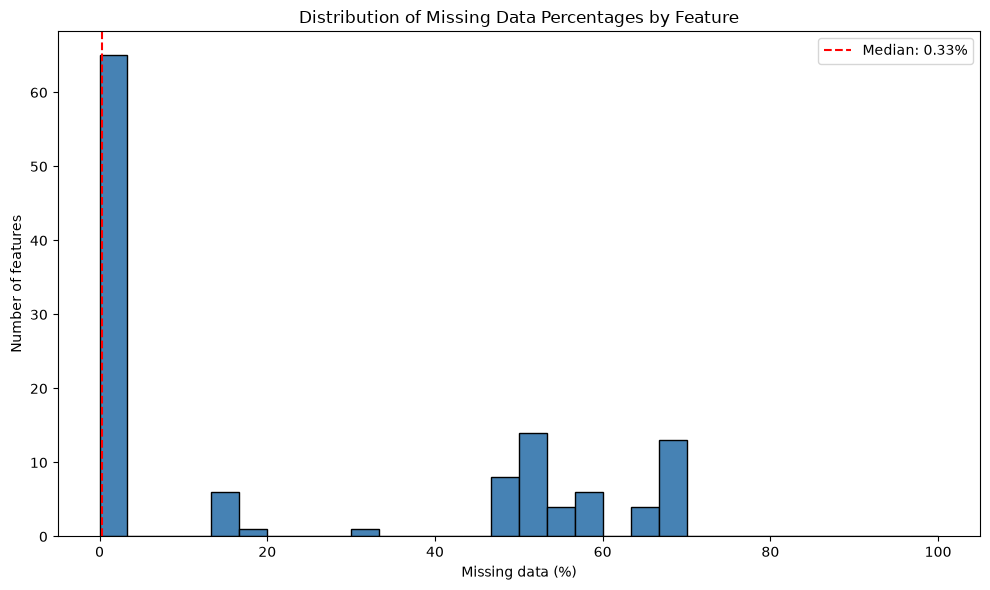

In [64]:
missing_total = application_train.isnull().sum()
missing_percent = (application_train.isnull().mean() * 100).sort_values(ascending=False)
data_types = application_train.dtypes

missing_data = pd.concat(
    [missing_total, missing_percent, data_types],
    axis=1,
    keys=["Total", "Percent missing", "Data Type"]
).sort_values("Percent missing", ascending=False)

# Visualize the distribution of missing data percentages by feature
missing_pct = application_train.isnull().mean() * 100

plt.figure(figsize=(10, 6))
plt.hist(missing_pct, bins=30, range=(0, 100), color="steelblue", edgecolor="black")
plt.title("Distribution of Missing Data Percentages by Feature")
plt.xlabel("Missing data (%)")
plt.ylabel("Number of features")
plt.axvline(
    missing_pct.median(),
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Median: {missing_pct.median():.2f}%"
)
plt.legend()
plt.tight_layout()
plt.show()



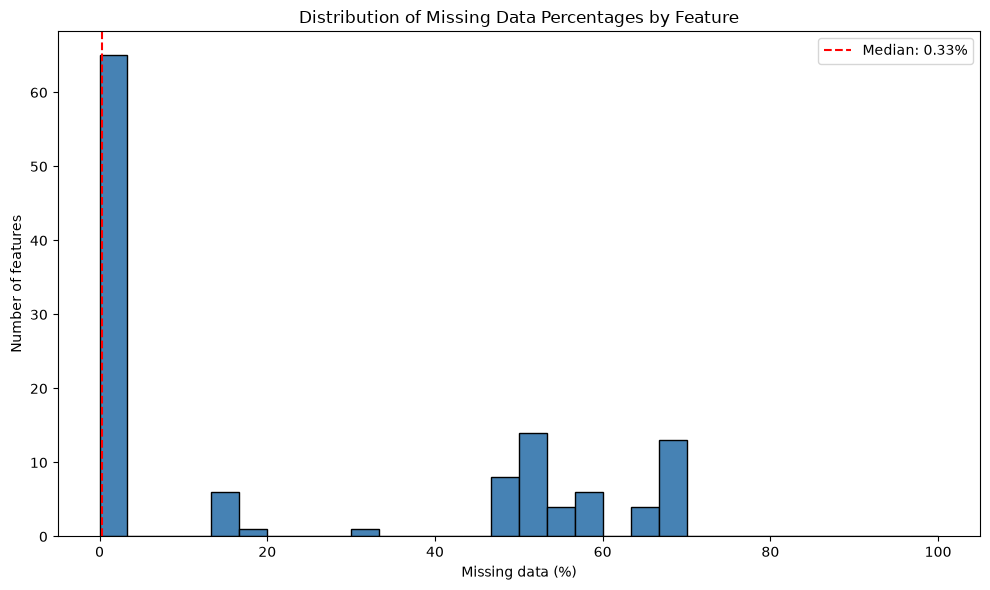

In [ ]:
features_to_drop = missing_data[missing_data["Percent missing"] > 10].index.tolist()

In [41]:
# Check for missing data in bureau balance
check_missing_data(bureau_balance)

,Total,Percent missing,Data Type
SK_ID_BUREAU,0,0.0,int64
MONTHS_BALANCE,0,0.0,int64
STATUS,0,0.0,str


In [42]:
# Check for missing data in bureau
check_missing_data(bureau)

,Total,Percent missing,Data Type
AMT_ANNUITY,1226791,71.473490,float64
AMT_CREDIT_MAX_OVERDUE,1124488,65.513264,float64
DAYS_ENDDATE_FACT,633653,36.916958,float64
AMT_CREDIT_SUM_LIMIT,591780,34.477415,float64
AMT_CREDIT_SUM_DEBT,257669,15.011932,float64
DAYS_CREDIT_ENDDATE,105553,6.149573,float64
AMT_CREDIT_SUM,13,0.000757,float64
CREDIT_ACTIVE,0,0.000000,str
CREDIT_CURRENCY,0,0.000000,str
DAYS_CREDIT,0,0.000000,int64


In [43]:
# Check for missing data in credit card balance
check_missing_data(credit_card_balance)

,Total,Percent missing,Data Type
AMT_PAYMENT_CURRENT,767988,19.998063,float64
AMT_DRAWINGS_ATM_CURRENT,749816,19.524872,float64
CNT_DRAWINGS_POS_CURRENT,749816,19.524872,float64
AMT_DRAWINGS_OTHER_CURRENT,749816,19.524872,float64
AMT_DRAWINGS_POS_CURRENT,749816,19.524872,float64
CNT_DRAWINGS_OTHER_CURRENT,749816,19.524872,float64
CNT_DRAWINGS_ATM_CURRENT,749816,19.524872,float64
CNT_INSTALMENT_MATURE_CUM,305236,7.948208,float64
AMT_INST_MIN_REGULARITY,305236,7.948208,float64
SK_ID_PREV,0,0.000000,int64


In [44]:
# check missing data in installments_payments
check_missing_data(installments_payments)

,Total,Percent missing,Data Type
DAYS_ENTRY_PAYMENT,2905,0.021352,float64
AMT_PAYMENT,2905,0.021352,float64
SK_ID_PREV,0,0.000000,int64
SK_ID_CURR,0,0.000000,int64
NUM_INSTALMENT_VERSION,0,0.000000,float64
NUM_INSTALMENT_NUMBER,0,0.000000,int64
DAYS_INSTALMENT,0,0.000000,float64
AMT_INSTALMENT,0,0.000000,float64


In [45]:
# Check for missing data in POS_CASH_balance
check_missing_data(POS_CASH_balance)

,Total,Percent missing,Data Type
CNT_INSTALMENT_FUTURE,26087,0.260835,float64
CNT_INSTALMENT,26071,0.260675,float64
SK_ID_PREV,0,0.000000,int64
SK_ID_CURR,0,0.000000,int64
MONTHS_BALANCE,0,0.000000,int64
NAME_CONTRACT_STATUS,0,0.000000,str
SK_DPD,0,0.000000,int64
SK_DPD_DEF,0,0.000000,int64


In [46]:
# Check for missing data in previous_application
check_missing_data(previous_application)

,Total,Percent missing,Data Type
RATE_INTEREST_PRIVILEGED,1664263,99.643698,float64
RATE_INTEREST_PRIMARY,1664263,99.643698,float64
AMT_DOWN_PAYMENT,895844,53.636480,float64
RATE_DOWN_PAYMENT,895844,53.636480,float64
NAME_TYPE_SUITE,820405,49.119754,str
NFLAG_INSURED_ON_APPROVAL,673065,40.298129,float64
DAYS_TERMINATION,673065,40.298129,float64
DAYS_LAST_DUE,673065,40.298129,float64
DAYS_LAST_DUE_1ST_VERSION,673065,40.298129,float64
DAYS_FIRST_DUE,673065,40.298129,float64


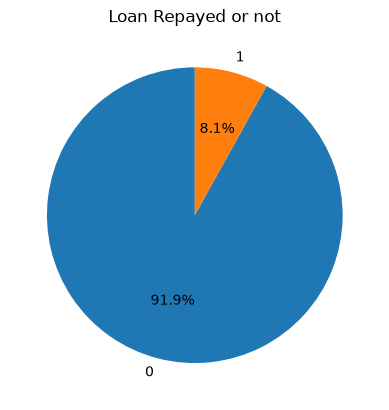

In [49]:
temp = application_train["TARGET"].value_counts()
df = pd.DataFrame({'labels': temp.index,
                   'values': temp.values
                  })

plt.pie(df['values'], labels=df['labels'], autopct='%1.1f%%', startangle=90)
plt.title('Loan Repayed or not')
plt.show()

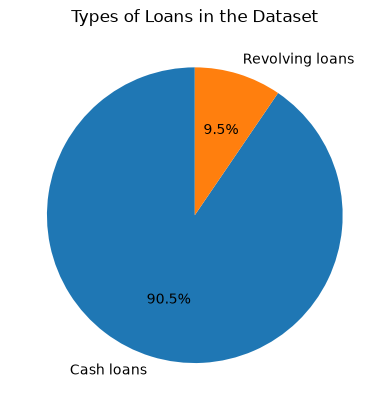

In [50]:

#Visualise types of loans in the dataset
temp = application_train["NAME_CONTRACT_TYPE"].value_counts()

df = pd.DataFrame({'labels': temp.index,
                   'values': temp.values
                  })

plt.pie(df['values'], labels=df['labels'], autopct='%1.1f%%', startangle=90)
plt.title('Types of Loans in the Dataset')
plt.show()

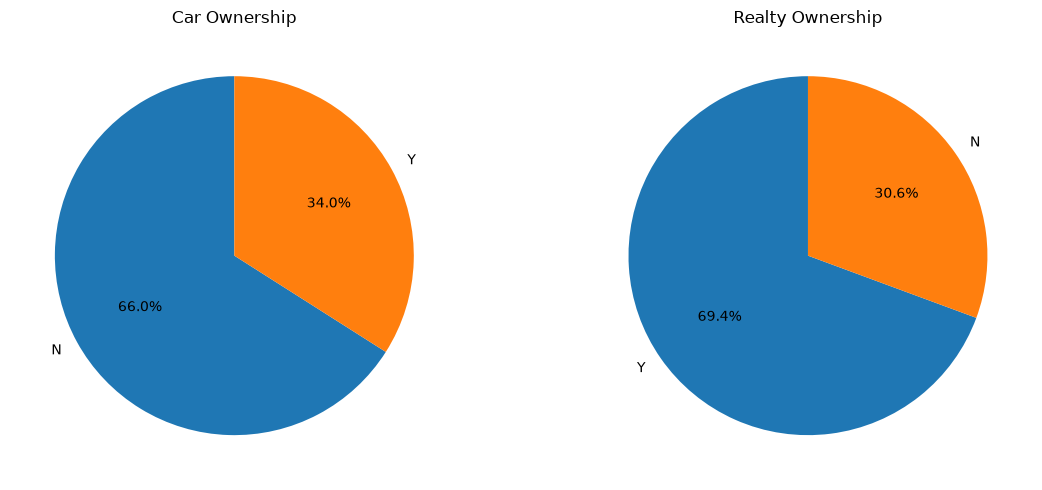

In [52]:
# plot breakdown of purpose of loans in the dataset
temp1 = application_train["FLAG_OWN_CAR"].value_counts()
temp2 = application_train["FLAG_OWN_REALTY"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot car ownership
df1 = pd.DataFrame({'labels': temp1.index, 'values': temp1.values})
axes[0].pie(df1['values'], labels=df1['labels'], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Car Ownership')

# Plot realty ownership
df2 = pd.DataFrame({'labels': temp2.index, 'values': temp2.values})
axes[1].pie(df2['values'], labels=df2['labels'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Realty Ownership')

plt.tight_layout()
plt.show()

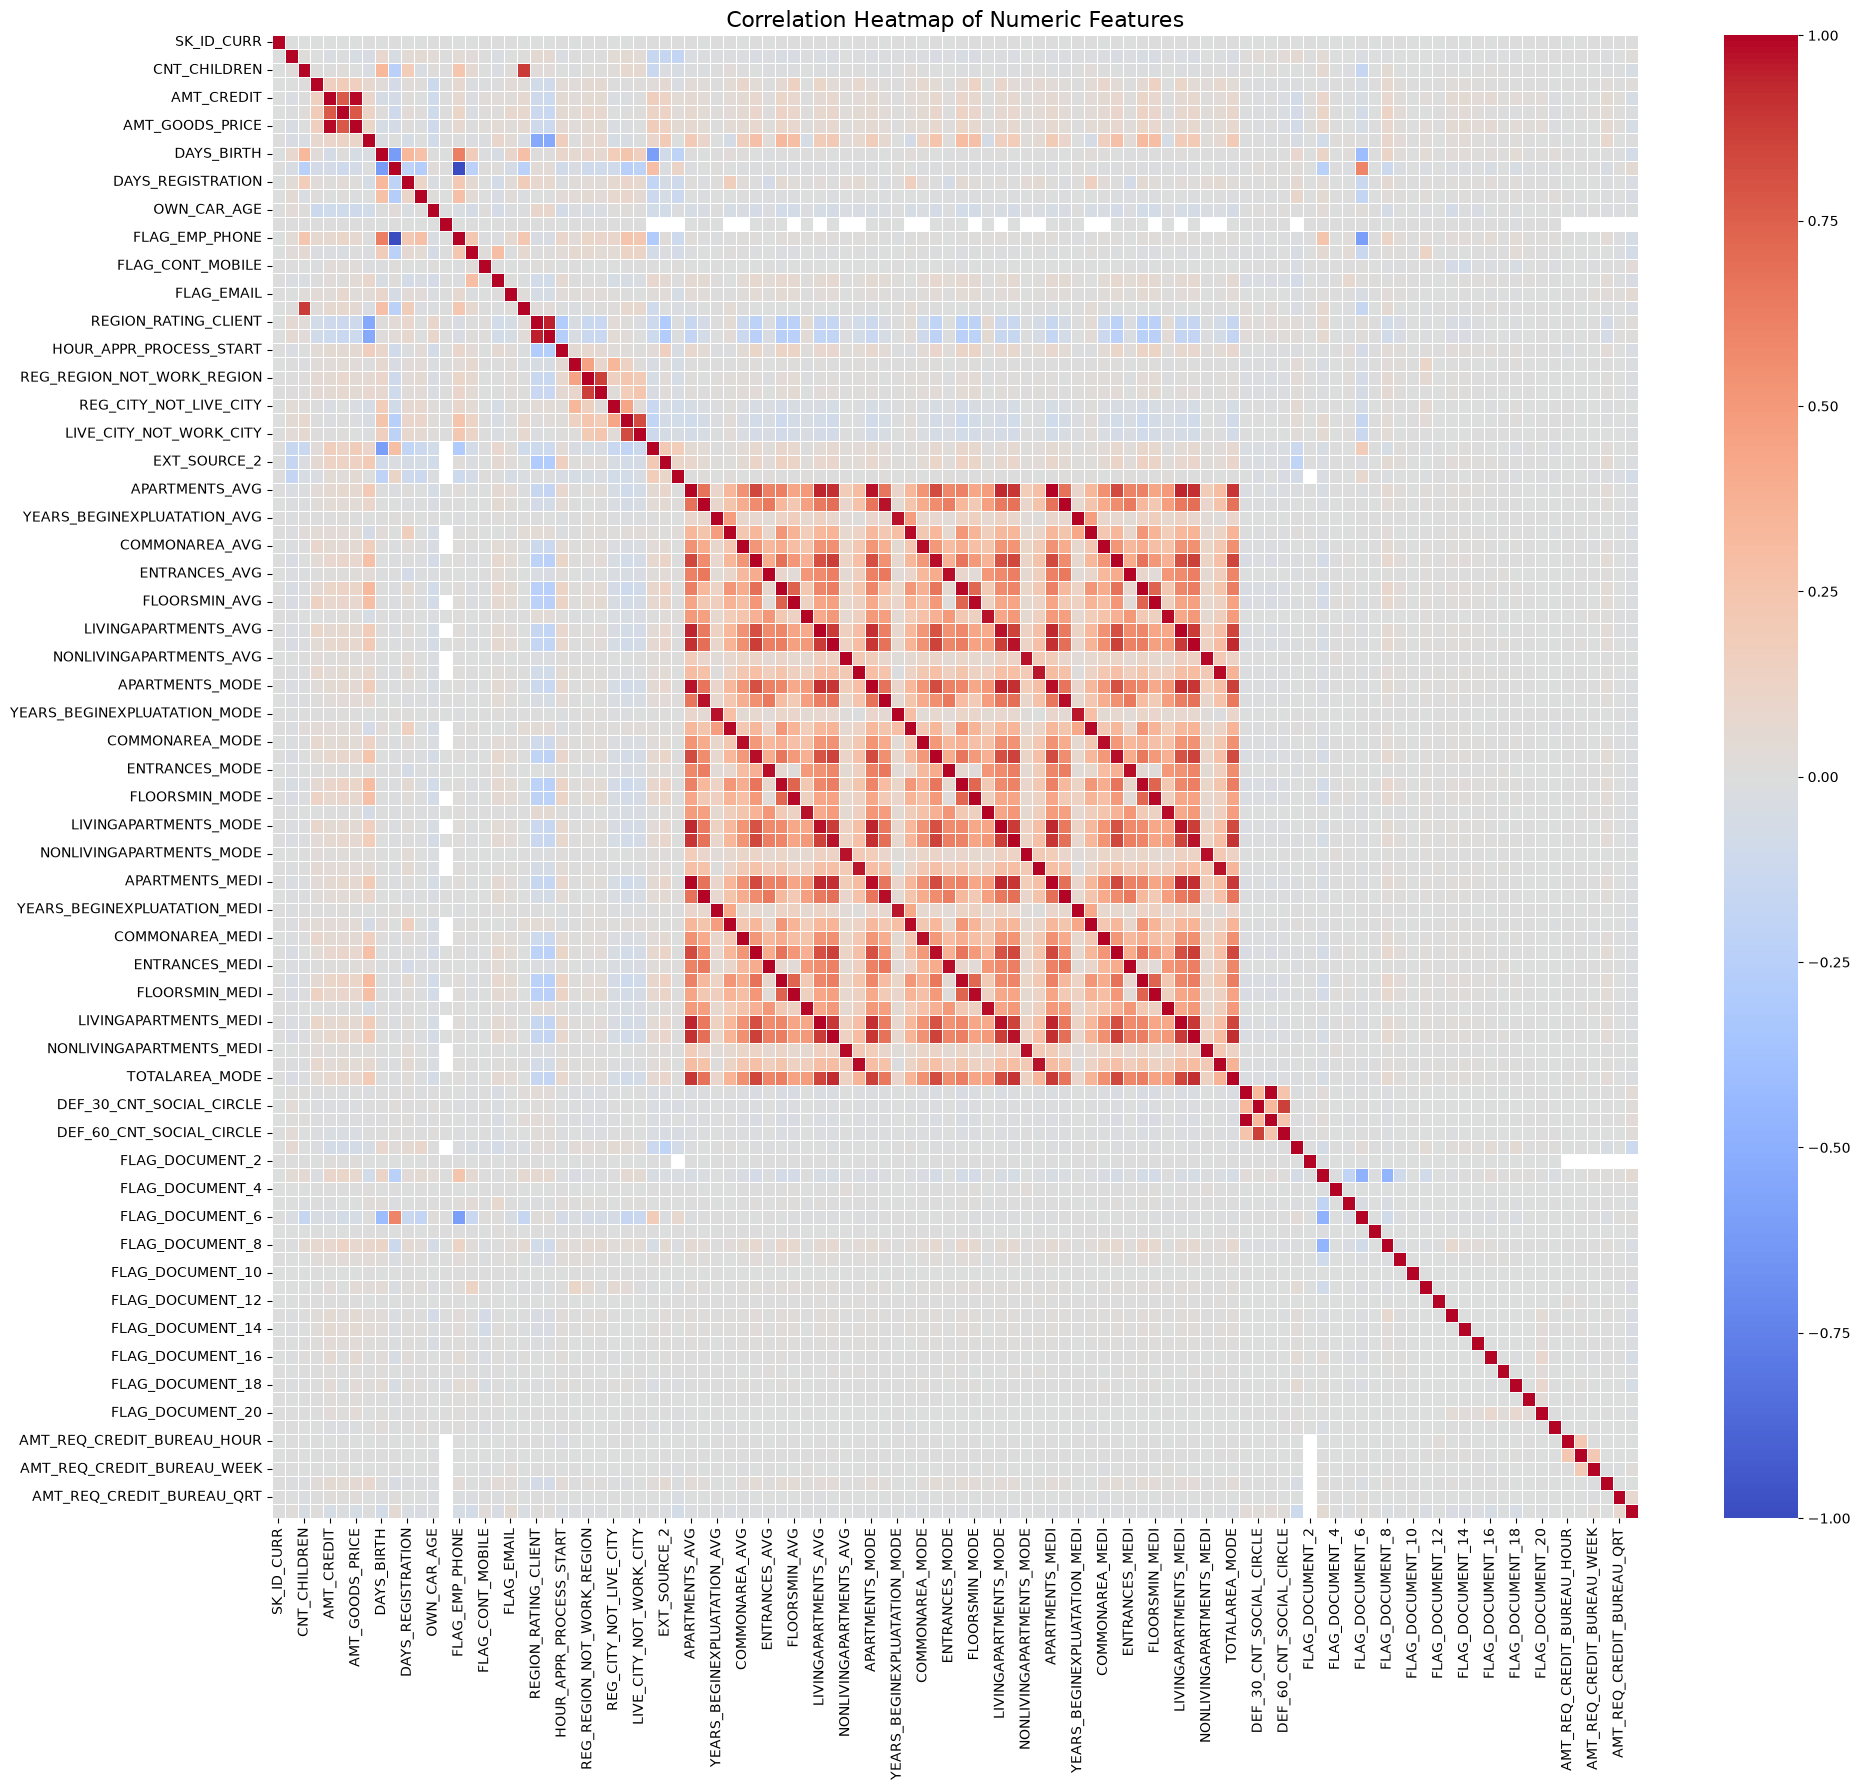

In [53]:
import seaborn as sns

# Select numeric columns only for correlation analysis
numeric_df = application_train.select_dtypes(include=["number"])

# Compute the correlation matrix
corr_matrix = numeric_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(20, 18))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    linewidths=0.5,
    square=False
)
plt.title("Correlation Heatmap of Numeric Features", fontsize=16)
plt.tight_layout()
plt.show()

In [54]:
# Feature importance using Random Forest Classifier
from sklearn import preprocessing
categorical_feats = [
    f for f in application_train.columns if application_train[f].dtype == 'object'
]

for col in categorical_feats:
    lb = preprocessing.LabelEncoder()
    lb.fit(list(application_train[col].values.astype('str')) + list(application_test[col].values.astype('str')))
    application_train[col] = lb.transform(list(application_train[col].values.astype('str')))
    application_test[col] = lb.transform(list(application_test[col].values.astype('str')))


In [55]:
application_train.fillna(-999, inplace = True)

TypeError: Invalid value '-999' for dtype 'str'. Value should be a string or missing value, got 'int' instead.

In [59]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=50, max_depth=8, min_samples_leaf=4, max_features=0.5, random_state=2018)
rf.fit(application_train.drop(['SK_ID_CURR', 'TARGET'],axis=1), application_train.TARGET)
features = application_train.drop(['SK_ID_CURR', 'TARGET'],axis=1).columns.values


ValueError: could not convert string to float: 'Cash loans'